# Nigerian Language ID: Inference API with Drift Monitoring

Serves the published model [`AbdulroqeebA/wavlm-base-plus-nigerian-lid`](https://huggingface.co/AbdulroqeebA/wavlm-base-plus-nigerian-lid) as a live API, logs every prediction, and flags when incoming audio stops looking like the audio the model was validated on.

Everything runs inside this notebook, in the same style as the DSN AI Bootcamp 2026 sessions on real-time inference (Olalekan Akinsande) and self-healing ML systems (Rashidat). The bootcamp examples used a resume-matching model; this notebook applies the same ideas to a **speech** model.

| Part | What happens | Bootcamp idea |
|---|---|---|
| 1. Setup | Install packages | environment |
| 2. Engine | Load the model once, one preprocessing function for every request | inference engine, no training/serving skew |
| 3. API | FastAPI server with `/health`, `/predict`, `/monitor`; every request is logged | deploy and log |
| 4. Reference | Record how the model behaves on clean validation clips | baseline |
| 5. Normal traffic | Send clean clips through the API | live traffic |
| 6. Drift report | Compare live behaviour with the baseline | drift detection |
| 7. Shifted traffic | Send the **same** clips again, degraded to phone quality, and watch the monitor | drift detected, retraining recommended |

**How to run:** use a **T4 GPU or CPU** runtime, then *Runtime → Run all*. Part 4 streams about 300 validation clips from Hugging Face, so allow a few minutes.

> The shifted audio in Part 7 is **simulated** (the same clips, degraded) (band-limited and noisy) to demonstrate the monitor. Thresholds are common rules of thumb, not tuned values.

## Part 1 · Setup

In [1]:
!pip -q install fastapi uvicorn python-multipart httpx librosa soundfile scipy

## Part 2 · The inference engine
The model and the preprocessing are defined **once** and used for every request, the same idea as the shared feature function in the bootcamp notebook. The preprocessing matches training: 16 kHz mono, centre-cropped to 10 seconds, padded to 10 seconds.

In [2]:
import io, time, json, threading, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch, librosa, soundfile as sf, httpx
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification

warnings.filterwarnings("ignore")

MODEL_ID = "AbdulroqeebA/wavlm-base-plus-nigerian-lid"
TARGET_SR = 16000
MAX_LEN = 10 * TARGET_SR

LANG_NAMES = {
    "yor": "Yoruba", "ibo": "Igbo", "hau": "Hausa", "ego": "Ego", "anw": "Anaang",
    "efi": "Efik", "ibb": "Ibibio", "idu": "Idoma", "igl": "Igala", "nup": "Nupe",
    "tiv": "Tiv", "urh": "Urhobo", "other": "Other",
}

class LIDEngine:
    """Loads the model once and serves predictions, like a production service."""
    def __init__(self, model_id=MODEL_ID):
        self.version = model_id
        self.fe = AutoFeatureExtractor.from_pretrained(model_id)
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.model = AutoModelForAudioClassification.from_pretrained(model_id).float().eval().to(self.device)
        self.id2label = self.model.config.id2label
        self.codes = [self.id2label[i] for i in range(len(self.id2label))]

    def prepare(self, audio):
        audio = np.asarray(audio, dtype=np.float32)
        if len(audio) > MAX_LEN:                      # centre-crop, as at validation time
            s = (len(audio) - MAX_LEN) // 2
            audio = audio[s:s + MAX_LEN]
        return audio

    def predict_array(self, audio):
        t0 = time.perf_counter()
        duration = len(audio) / TARGET_SR
        audio = self.prepare(audio)
        inputs = self.fe(audio, sampling_rate=TARGET_SR, max_length=MAX_LEN,
                         truncation=True, padding="max_length", return_tensors="pt")
        inputs = {k: v.to(self.device) for k, v in inputs.items()}
        with torch.no_grad():
            logits = self.model(**inputs).logits[0]
        probs = torch.softmax(logits, dim=-1).cpu().numpy()
        order = probs.argsort()[::-1]
        top3 = [{"code": self.codes[i], "language": LANG_NAMES.get(self.codes[i], self.codes[i]),
                 "prob": round(float(probs[i]), 4)} for i in order[:3]]
        return {
            "model_version": self.version,
            "top3": top3,
            "top1": self.codes[order[0]],
            "confidence": float(probs[order[0]]),
            "margin": float(probs[order[0]] - probs[order[1]]),
            "entropy": float(-(probs * np.log(probs + 1e-12)).sum()),
            "duration_s": round(duration, 2),
            "rms": float(np.sqrt(np.mean(audio ** 2))) if len(audio) else 0.0,
            "flatness": float(np.mean(librosa.feature.spectral_flatness(y=audio))) if len(audio) else 0.0,
            "latency_ms": round((time.perf_counter() - t0) * 1000, 1),
        }

ENGINE = LIDEngine()
ENGINE.predict_array(np.zeros(TARGET_SR, dtype=np.float32))   # warm-up so the first real request is not slow
print("Engine loaded:", ENGINE.version, "| classes:", len(ENGINE.codes), "| running on:", ENGINE.device.upper())

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  189MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/252 [00:00<?, ?it/s]

Engine loaded: AbdulroqeebA/wavlm-base-plus-nigerian-lid | classes: 13 | running on: CUDA


## Part 3 · Serve it as an API (and log every prediction)
Same pattern as the bootcamp's "serve the engine from inside the notebook" step. Every call to `/predict` appends a record to `PRED_LOG`. That log is what the drift monitor reads.

In [3]:
from fastapi import FastAPI, UploadFile, File, HTTPException
import uvicorn

try:
    server.should_exit = True      # stop an older server if this cell is run again
    time.sleep(1)
except NameError:
    pass

PRED_LOG = []          # one dict per prediction (the monitoring data)

def log_prediction(rec, source):
    PRED_LOG.append({"ts": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                     "source": source, **{k: v for k, v in rec.items() if k != "top3"}})

api = FastAPI(title="Nigerian LID API", version="1.0")

@api.get("/health")
def health():
    return {"status": "ok", "model": ENGINE.version, "logged_predictions": len(PRED_LOG)}

@api.post("/predict")
def predict(file: UploadFile = File(...)):
    data = file.file.read()
    try:
        audio, _ = librosa.load(io.BytesIO(data), sr=TARGET_SR, mono=True)
    except Exception:
        raise HTTPException(400, "Could not read this audio. Use WAV, FLAC or OGG.")
    if len(audio) < TARGET_SR // 10:
        raise HTTPException(400, "Clip is too short (under 0.1 seconds).")
    rec = ENGINE.predict_array(audio)
    log_prediction(rec, source="live")
    return rec

@api.get("/monitor")
def monitor(last: int = 200):
    df = pd.DataFrame([r for r in PRED_LOG if r["source"] == "live"]).tail(last)
    if df.empty:
        return {"n": 0}
    return {"n": int(len(df)), "mean_confidence": round(float(df.confidence.mean()), 3),
            "low_confidence_rate": round(float((df.confidence < 0.5).mean()), 3),
            "class_counts": df.top1.value_counts().to_dict()}

PORT = 8766
server = uvicorn.Server(uvicorn.Config(api, host="127.0.0.1", port=PORT, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
for _ in range(100):
    if server.started: break
    time.sleep(0.1)
print(f"API running: http://127.0.0.1:{PORT}/docs   (stop with: server.should_exit = True)")
print(httpx.get(f"http://127.0.0.1:{PORT}/health").json())

API running: http://127.0.0.1:8766/docs   (stop with: server.should_exit = True)
{'status': 'ok', 'model': 'AbdulroqeebA/wavlm-base-plus-nigerian-lid', 'logged_predictions': 0}


## Part 4 · Reference baseline
We need to know what "normal" looks like. Here we stream 300 validation clips, run the first 150 through the engine, and record the results as the **reference**. The other 150 become the live traffic in Parts 5 and 7, so the "normal" and "shifted" runs use **exactly the same clips**.

In [4]:
from datasets import load_dataset, Audio
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")      # read from Colab Secrets, never typed into the code
except Exception:
    HF_TOKEN = None

stream = load_dataset("Data-Science-Nigeria/dsn-2026-lid-train", split="validation",
                      streaming=True, token=HF_TOKEN)
stream = stream.cast_column("audio", Audio(sampling_rate=TARGET_SR))
stream = stream.shuffle(seed=42, buffer_size=1000)

clips = []
for ex in stream.take(300):
    clips.append((ENGINE.prepare(ex["audio"]["array"]), ex["label"]))
print("Loaded", len(clips), "clips")

REF, NORMAL = clips[:150], clips[150:300]

for audio, label in REF:
    log_prediction(ENGINE.predict_array(audio), source="reference")

ref_df = pd.DataFrame([r for r in PRED_LOG if r["source"] == "reference"])
ref_acc = np.mean([r.top1 == y for r, (_, y) in zip(ref_df.itertuples(), REF)])
print(f"Reference: mean confidence {ref_df.confidence.mean():.3f} | "
      f"low-confidence rate {(ref_df.confidence < 0.5).mean():.1%} | accuracy {ref_acc:.1%}")

README.md:   0%|          | 0.00/4.68k [00:00<?, ?B/s]

Loaded 300 clips
Reference: mean confidence 0.671 | low-confidence rate 20.7% | accuracy 58.7%


## Part 5 · Send normal traffic through the API
These calls go over HTTP to the API running in this notebook, like a real client would. The true labels are **not** sent, because in production you do not get labels back.

In [5]:
def to_wav_bytes(audio):
    buf = io.BytesIO()
    sf.write(buf, audio, TARGET_SR, format="WAV")
    return buf.getvalue()

def send_batch(batch, transform=None):
    answers = []
    for i, (audio, label) in enumerate(batch):
        a = transform(audio, i) if transform else audio
        r = httpx.post(f"http://127.0.0.1:{PORT}/predict",
                       files={"file": ("clip.wav", to_wav_bytes(a), "audio/wav")}, timeout=60)
        r.raise_for_status()
        answers.append(r.json())
    acc = np.mean([a["top1"] == y for a, (_, y) in zip(answers, batch)])
    return answers, acc

normal_answers, normal_acc = send_batch(NORMAL)
lat = [a["latency_ms"] for a in normal_answers]
print(f"Sent {len(NORMAL)} clips | accuracy {normal_acc:.1%} (only known because we kept the labels) | "
      f"latency p50 {np.percentile(lat, 50):.0f} ms, max {max(lat):.0f} ms | device: {ENGINE.device}")
print(httpx.get(f"http://127.0.0.1:{PORT}/monitor").json())

Sent 150 clips | accuracy 69.3% (only known because we kept the labels) | latency p50 63 ms, max 132 ms | device: cuda
{'n': 150, 'mean_confidence': 0.669, 'low_confidence_rate': 0.167, 'class_counts': {'other': 59, 'urh': 48, 'hau': 16, 'igl': 8, 'efi': 5, 'ibo': 5, 'tiv': 5, 'idu': 3, 'nup': 1}}


## Part 6 · Drift detection
Four simple signals compare recent live traffic with the reference. None of them needs labels.

| Signal | What it catches | Flag when |
|---|---|---|
| Class-mix PSI | the model suddenly predicts a different mix of languages | PSI above 0.25 |
| Confidence KS test | the whole confidence distribution has shifted | p-value below 0.01 |
| Low-confidence rate | more clips the model is unsure about | up by more than 15 percentage points |
| Audio-noisiness KS test | the **input audio itself** changed (more noise or hiss), whatever the model says | p-value below 0.01 |

Two lessons from a first run are built in: PSI is jumpy with only 150 clips, so rare classes are pooled into one group before it is computed; and model confidence can stay flat while accuracy drops, so one signal looks at the audio directly (spectral flatness, higher for noisier audio).

Status: **DRIFT** if 2 or more signals fire, **WATCH** if 1, otherwise **OK**.

In [6]:
def psi(ref_counts, live_counts, eps=1e-3):
    r = np.clip(ref_counts / ref_counts.sum(), eps, None)
    l = np.clip(live_counts / live_counts.sum(), eps, None)
    return float(np.sum((l - r) * np.log(l / r)))

def drift_report(window=150, show=True):
    ref = pd.DataFrame([r for r in PRED_LOG if r["source"] == "reference"])
    live = pd.DataFrame([r for r in PRED_LOG if r["source"] == "live"]).tail(window)

    # Pool classes that are rare in the reference (under 5%) so empty bins do not dominate PSI
    share = ref.top1.value_counts(normalize=True)
    keep = [c for c in ENGINE.codes if share.get(c, 0) >= 0.05]
    def grouped(df):
        counts = df.top1.value_counts()
        vals = [counts.get(c, 0) for c in keep] + [sum(v for c, v in counts.items() if c not in keep)]
        return np.array(vals, dtype=float)
    psi_v = psi(grouped(ref), grouped(live))

    ks_conf = float(ks_2samp(ref.confidence, live.confidence).pvalue)
    ks_flat = float(ks_2samp(ref.flatness, live.flatness).pvalue)
    low_ref, low_live = float((ref.confidence < 0.5).mean()), float((live.confidence < 0.5).mean())

    signals = {
        f"class mix PSI = {psi_v:.2f}": psi_v > 0.25,
        f"confidence KS p = {ks_conf:.4f}": ks_conf < 0.01,
        f"low-confidence rate {low_ref:.0%} -> {low_live:.0%}": (low_live - low_ref) > 0.15,
        f"audio noisiness KS p = {ks_flat:.4f}": ks_flat < 0.01,
    }
    fired = sum(signals.values())
    status = "DRIFT" if fired >= 2 else "WATCH" if fired == 1 else "OK"
    if show:
        print(f"Drift status: {status}   (live window = last {len(live)} predictions)")
        for name, flag in signals.items():
            print(f"  {'FIRED' if flag else 'ok   '}  {name}")
        print(f"  mean confidence: reference {ref.confidence.mean():.3f} | live {live.confidence.mean():.3f}")
        print(f"  median noisiness (spectral flatness): reference {ref.flatness.median():.4f} | live {live.flatness.median():.4f}")
    return status, ref, live

status, ref_df, live_df = drift_report()

Drift status: OK   (live window = last 150 predictions)
  ok     class mix PSI = 0.11
  ok     confidence KS p = 0.1391
  ok     low-confidence rate 21% -> 17%
  ok     audio noisiness KS p = 0.8943
  mean confidence: reference 0.671 | live 0.669
  median noisiness (spectral flatness): reference 0.0681 | live 0.0680


## Part 7 · Shifted traffic: does the monitor notice?
We take the **same 150 clips** that were just sent as normal traffic, degrade them to sound like a poor phone recording (limited bandwidth plus background noise), and send them through the API again. Because the clips are identical, any change in accuracy comes from the degradation itself. The monitor never sees a label.

Same 150 clips: accuracy 69.3% (clean) -> 52.0% (degraded)
36 clips went from right to wrong, 10 went from wrong to right
(In production you would not know this. The monitor below works without labels.)

Drift status: WATCH   (live window = last 150 predictions)
  ok     class mix PSI = 0.21
  ok     confidence KS p = 0.8943
  ok     low-confidence rate 21% -> 24%
  FIRED  audio noisiness KS p = 0.0000
  mean confidence: reference 0.671 | live 0.667
  median noisiness (spectral flatness): reference 0.0681 | live 0.3324
Recommended action: keep watching; review a sample of recent clips by ear.


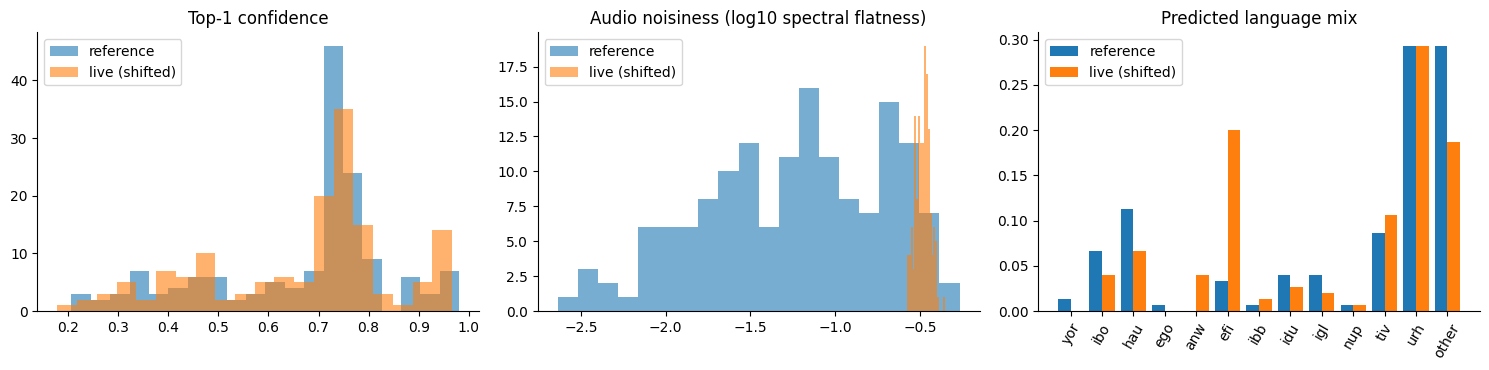

In [7]:
def degrade(audio, i, snr_db=5):
    rng = np.random.default_rng(i)
    a = librosa.resample(librosa.resample(audio, orig_sr=TARGET_SR, target_sr=8000),
                         orig_sr=8000, target_sr=TARGET_SR)          # band-limit to about 4 kHz
    noise_power = (np.mean(a ** 2) + 1e-12) / (10 ** (snr_db / 10))
    return (a + rng.normal(0, np.sqrt(noise_power), size=a.shape)).astype("float32")

shift_answers, shift_acc = send_batch(NORMAL, transform=degrade)

labels = [y for _, y in NORMAL]
was_right = [a["top1"] == y for a, y in zip(normal_answers, labels)]
now_right = [a["top1"] == y for a, y in zip(shift_answers, labels)]
broke = sum(w and not n for w, n in zip(was_right, now_right))
fixed = sum(n and not w for w, n in zip(was_right, now_right))
print(f"Same 150 clips: accuracy {normal_acc:.1%} (clean) -> {shift_acc:.1%} (degraded)")
print(f"{broke} clips went from right to wrong, {fixed} went from wrong to right")
print("(In production you would not know this. The monitor below works without labels.)\n")

status, ref_df, live_df = drift_report()

def recommend(status):
    if status == "DRIFT":
        return ("Recommended action: collect and label recent clips, add them (with this kind of noise "
                "augmentation) to training, retrain, compare macro F1 on a fixed test set, then publish as v2.")
    if status == "WATCH":
        return "Recommended action: keep watching; review a sample of recent clips by ear."
    return "Recommended action: none."
print(recommend(status))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(ref_df.confidence, bins=20, alpha=.6, label="reference")
ax[0].hist(live_df.confidence, bins=20, alpha=.6, label="live (shifted)")
ax[0].set_title("Top-1 confidence"); ax[0].legend()
ax[1].hist(np.log10(ref_df.flatness + 1e-8), bins=20, alpha=.6, label="reference")
ax[1].hist(np.log10(live_df.flatness + 1e-8), bins=20, alpha=.6, label="live (shifted)")
ax[1].set_title("Audio noisiness (log10 spectral flatness)"); ax[1].legend()
codes = ENGINE.codes
x = np.arange(len(codes))
ax[2].bar(x - .2, ref_df.top1.value_counts(normalize=True).reindex(codes, fill_value=0), .4, label="reference")
ax[2].bar(x + .2, live_df.top1.value_counts(normalize=True).reindex(codes, fill_value=0), .4, label="live (shifted)")
ax[2].set_xticks(x); ax[2].set_xticklabels(codes, rotation=60); ax[2].set_title("Predicted language mix"); ax[2].legend()
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [8]:
# Save the prediction log, then stop the API
Path("logs").mkdir(exist_ok=True)
pd.DataFrame(PRED_LOG).to_csv("logs/predictions.csv", index=False)
print("Saved", len(PRED_LOG), "log rows to logs/predictions.csv")
server.should_exit = True

Saved 450 log rows to logs/predictions.csv


**Notes**
- Results depend on the clips streamed and the shifted audio is simulated, so treat the numbers as a demonstration of the monitoring idea, not a benchmark.
- Credits: pattern adapted from the DSN AI Bootcamp 2026 sessions *Real-Time Machine Learning: Building and Deploying an Inference System* (Olalekan Akinsande) and *Building Self-Healing ML Systems* (Rashidat). Model, data handling, monitoring logic and speech application by the project team.
- Dataset: `Data-Science-Nigeria/dsn-2026-lid-train` (mixed per-source licenses; no audio is redistributed here).